# Exp16 v3 — Residual-stream patching at depth (IOI): Exp13 prompts, FR / DE / HI

Supersedes v1 and v2. **Results go to `exp16_v3_results/`.** v1/v2 results came from prompts that were *not* Exp13's (see below) and must not be mixed with v3.

**Question.** For IOI, are residual-stream states *causally interchangeable* between EN and a target language at every depth, or does interchangeability break somewhere in the stack? This is a computational-interchangeability test, not a representational-similarity test.

**Method.** Patch the final-position residual at the end of layer `L` in a target-language forward pass with the matched EN donor activation. `compat(L) = (patched − ablated) / (clean − ablated)`, scored on the target prompt's own IO / S name tokens.

## What changed from v2, and why

| # | Problem in v1/v2 | v3 |
|---|---|---|
| 1 | **Prompts were my own, not Exp13's** (the v1 comment claiming "Exp13 / Exp14 inventory" was wrong). | **EN and FR templates are Exp13's, embedded verbatim** from your Exp13 notebook. Names are reproduced by Exp13's exact procedure (`"a " + name` single-token test with unique ids, `Random(7)` shuffle, first 20). DE and HI do not exist in Exp13, so those 6 + 6 templates are **my translations** of Exp13's six EN templates. |
| 2 | **Positional shortcut.** v1/v2 always listed the repeated subject first and the IO second, so "pick the second-listed name" solves the task. Exp13 randomises it. | Order of `N1`/`N2` is randomised per prompt exactly as in Exp13 (IO first or second with p = 0.5). Donor and target share the same order. Baseline accuracy is reported **split by IO position**. |
| 3 | `hi_native`: only 3 of 30 Devanagari names are single-token (measured with your tokenizer), so the condition cannot be run under single-token scoring. | **Dropped.** HI uses EN names in HI templates (the Exp14 `YOs` convention). No multi-token substitution. |
| 4 | Models loaded with the default attention implementation. | `attn_implementation="eager"` as in Exp13 (recommended for Gemma-2). |
| 5 | Only means were saved, so the FR floor failure could not be diagnosed. | Per-prompt arrays saved to `.npz`; a **per-template breakdown** prints floor and cross at the checkpoint layers; floor is also shown donor-normalised. |

Kept from v2: every template within a language ends in one identical token (EN `to`, FR `à`, DE `an`, HI `ने`); cross and floor share the identical target prompt; floor checked at every L (untrusted layers shaded); compat is `NaN` where `|clean − ablated| < DEN_MIN`; cache files carry a spec hash.

## How to read the curves

- **At `L = n_layers − 1` compat is a tautology.** Patching the last layer's output at the final position reproduces the donor's output logits, so cross compat there = (donor logit-diff) / (target logit-diff), a *confidence ratio*. Above 1 only means the EN prompt is more confident. The dotted lines are **donor-normalised** (`(patched − ablated) / (donor_clean − ablated)`).
- **Floor at the last layer is ≈ 1 up to sampling noise** (it is mean donor / mean target logit-diff with balanced templates). The informative floor deviations are at middle layers.
- **Low cross compat at L ≈ 0–4 is expected**: the final position still mostly encodes its own token (`to` vs `à` vs `an` vs `ने`). That is token-identity substitution, not a language-specific stage. The question is what happens *after* it recovers.

**Controls (none optional).** Self-test (identity patch ≈ 1) → floor at every L → baseline ≥ 0.75 on the target language per scale.

Run top to bottom: **PREFLIGHT**, then **RUN 1** (2B). Inspect, check the decision rules, then **RUN 2**.

## Environment

In [1]:
import os
os.environ["http_proxy"]  = "http://proxy61.iitd.ac.in:3128"
os.environ["https_proxy"] = "http://proxy61.iitd.ac.in:3128"
os.environ["HF_TOKEN"] = os.environ.get("HF_TOKEN", "<REDACTED>")


In [2]:
import os
# CUDA_VISIBLE_DEVICES must be set BEFORE importing torch (project convention: GPU 2).
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

import gc, hashlib, json, random, time, warnings
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

warnings.filterwarnings("ignore", category=UserWarning)
torch.set_grad_enabled(False)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.bfloat16

print(f"torch={torch.__version__}  device={DEVICE}  dtype={DTYPE}")
if torch.cuda.is_available():
    gib = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"gpu: {torch.cuda.get_device_name(0)}  mem={gib:.1f} GiB")

/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch=2.11.0+cu130  device=cuda  dtype=torch.bfloat16
gpu: NVIDIA H200 NVL  mem=139.8 GiB


In [3]:
MODEL_SPECS = {
    "2b_base": "google/gemma-2-2b",        # no local folder on this machine; HF hub id
    "9b_base": "/home/models/gemma-2-9b",
    "9b_it":   "/home/models/gemma-2-9b-it",
    "27b_it":  "/home/models/gemma-2-27b-it",
}

SEEDS        = [0, 7, 13]                  # Exp13 / 14 convention
N_PROMPTS    = 120                         # must be divisible by 6 (20 per template, as in Exp13's build())
TARGET_LANGS = ["fr", "de", "hi"]          # donor is always EN; EN names in every target template

N_NAMES      = 20                          # Exp13 used 20 names per language (limited by Yoruba)
NAME_SHUFFLE_SEED = 7                      # Exp13: random.Random(7).shuffle(names)
EXP13_EN_SINGLE_TOKEN = 45                 # Exp13 printed: single-token names {'en': 45, ...}

SPEC_VERSION = "v3"
RESULTS_DIR  = Path("exp16_v3_results")    # NEW dir: earlier versions used non-Exp13 prompts
RESULTS_DIR.mkdir(exist_ok=True)
EXP14_DIR    = Path("exp14_results")       # optional, provenance only

BASELINE_MIN = 0.75     # target-language IOI accuracy gate
FLOOR_LO, FLOOR_HI = 0.9, 1.1
DEN_MIN      = 1.0      # |clean - ablated| (logits) below this -> compat = NaN (untrusted)
MIN_NAMES    = 10

assert N_PROMPTS % 6 == 0
print(f"results dir: {RESULTS_DIR.resolve()}  (spec {SPEC_VERSION})")

results dir: /home/anwoy/exp16_v3_results  (spec v3)


## Names and templates

**EN and FR: Exp13's, verbatim.** Placeholders are `{N1}`, `{N2}` (the two listed names, order randomised) and `{S}` (the repeated subject; the IO is the other name). EN templates all end in `to`, FR in `à`.

**DE and HI: my translations** of Exp13's six EN templates, same event structure, same placeholders. Within each language every template ends in the same token (DE `an`, HI `ने`) so the floor control is fair at low L. Hindi is SOV: the IO precedes the verb, so the HI prompt stops at the ergative `ने` and the IO name is the natural next token; the object being given is therefore not stated in HI prompts.

**Names.** EN names only (Exp14 matched convention: the correct next token is the same token on donor and target side). The 20 names are reproduced with Exp13's procedure so they are the same names as Exp13 on the same tokenizer.

In [4]:
EN_NAMES_ALL = [
    "James",
    "John",
    "Robert",
    "Michael",
    "William",
    "David",
    "Richard",
    "Thomas",
    "Mary",
    "Patricia",
    "Jennifer",
    "Linda",
    "Elizabeth",
    "Barbara",
    "Susan",
    "Jessica",
    "Sarah",
    "Karen",
    "Daniel",
    "Mark",
    "Paul",
    "Steven",
    "Kevin",
    "Brian",
    "George",
    "Anna",
    "Laura",
    "Emma",
    "Alice",
    "Julia",
    "Peter",
    "Henry",
    "Frank",
    "Kate",
    "Lucy",
    "Ruth",
    "Helen",
    "Carol",
    "Diane",
    "Grace",
    "Rose",
    "Edward",
    "Andrew",
    "Joseph",
    "Charles",
]   # Exp13 NAMES["en"], verbatim

EN_TEMPLATES = [
    "When {N1} and {N2} went to the store, {S} gave a drink to",
    "Then, {N1} and {N2} had a lot of fun at the school. {S} gave a ball to",
    "After {N1} and {N2} went to the park, {S} handed a book to",
    "Yesterday {N1} and {N2} visited the office, and {S} sent a letter to",
    "While {N1} and {N2} were at the market, {S} offered some fruit to",
    "Today {N1} and {N2} met in the garden. Afterwards, {S} showed the photos to",
]   # Exp13, verbatim (all end in "to")

FR_TEMPLATES = [
    "Quand {N1} et {N2} sont allés au marché, {S} a donné une pomme à",
    "Ensuite, {N1} et {N2} se sont bien amusés à l'école. {S} a donné un ballon à",
    "Après que {N1} et {N2} sont allés au parc, {S} a prêté un livre à",
    "Hier, {N1} et {N2} ont visité le bureau, et {S} a envoyé une lettre à",
    "Pendant que {N1} et {N2} étaient au marché, {S} a offert des fruits à",
    "Aujourd'hui, {N1} et {N2} se sont retrouvés dans le jardin. Ensuite, {S} a montré les photos à",
]   # Exp13, verbatim (all end in "à")

DE_TEMPLATES = [   # MY translations of the six Exp13 EN templates; all end in "an"
    "Als {N1} und {N2} in den Laden gingen, gab {S} ein Getränk an",
    "Dann hatten {N1} und {N2} viel Spaß in der Schule. {S} gab einen Ball an",
    "Nachdem {N1} und {N2} in den Park gegangen waren, reichte {S} ein Buch an",
    "Gestern besuchten {N1} und {N2} das Büro, und {S} schickte einen Brief an",
    "Während {N1} und {N2} auf dem Markt waren, gab {S} etwas Obst an",
    "Heute trafen sich {N1} und {N2} im Garten. Danach reichte {S} die Fotos an",
]

HI_TEMPLATES = [   # MY translations of the six Exp13 EN templates; all end in "ने" (IO name is the next token)
    "जब {N1} और {N2} दुकान गए, तो {S} ने",
    "फिर {N1} और {N2} ने स्कूल में बहुत मज़ा किया। {S} ने",
    "{N1} और {N2} के पार्क जाने के बाद, {S} ने",
    "कल {N1} और {N2} दफ़्तर गए, और {S} ने",
    "जब {N1} और {N2} बाज़ार में थे, तब {S} ने",
    "आज {N1} और {N2} बगीचे में मिले। उसके बाद, {S} ने",
]

TEMPLATES = {"en": EN_TEMPLATES, "fr": FR_TEMPLATES, "de": DE_TEMPLATES, "hi": HI_TEMPLATES}
assert all(len(v) == 6 for v in TEMPLATES.values()), "each language needs exactly 6 templates"

In [5]:
class LangUnavailable(Exception):
    """Raised when a condition cannot be built cleanly (too few usable single-token names)."""


_NAME_CACHE = {}


def get_en_names(tok):
    """Reproduce Exp13: single-token test on ('a ' + name) with unique ids, Random(7) shuffle, first N_NAMES.
    Returns [(name, token_id)]. Also returns how many single-token names existed (Exp13 reported 45)."""
    key = id(tok)
    if key in _NAME_CACHE:
        return _NAME_CACHE[key]
    out, nid, seen = [], {}, set()
    for n in EN_NAMES_ALL:
        ids = tok.encode("a " + n, add_special_tokens=False)
        if len(ids) == 2 and ids[1] not in seen:
            out.append(n); nid[n] = ids[1]; seen.add(ids[1])
    n_single = len(out)
    random.Random(NAME_SHUFFLE_SEED).shuffle(out)
    chosen = [(n, nid[n]) for n in out[:N_NAMES]]
    if len(chosen) < MIN_NAMES:
        raise LangUnavailable(f"only {len(chosen)} usable single-token EN names (< {MIN_NAMES})")
    _NAME_CACHE[key] = (chosen, n_single)
    return _NAME_CACHE[key]


def spec_hash(lang):
    blob = json.dumps({
        "tgt_tpl": TEMPLATES[lang], "en_tpl": TEMPLATES["en"],
        "names_all": EN_NAMES_ALL, "n_names": N_NAMES, "name_seed": NAME_SHUFFLE_SEED,
        "scheme": "v3-exp13-prompts-counterbalanced-shared-target-cyclic-floor",
    }, ensure_ascii=False, sort_keys=True)
    return hashlib.md5(blob.encode("utf-8")).hexdigest()[:12]

In [6]:
def build_pairs(tok, lang, n_prompts, seed):
    """Built like Exp13's build(): per template, `per` prompts; io, s = rng.sample(names, 2); the listed order
       (N1, N2) is (io, s) or (s, io) with p = 0.5 (so IO position is counterbalanced).
       Per pair (template t):
         target_prompt : target-language template t         (scored here)
         donor_cross   : EN template t, SAME names, SAME order  (cross donor)
         donor_floor   : target-language template (t+1) % 6, SAME names, SAME order  (floor donor)
       Cross and floor share the identical target prompt; only the donor differs. All donors/targets use the
       same EN name tokens, so io_id / s_id are valid readout tokens on both sides."""
    assert n_prompts % 6 == 0
    names, _ = get_en_names(tok)
    tgt_tpl, en_tpl = TEMPLATES[lang], TEMPLATES["en"]
    rng = random.Random(seed)
    per = n_prompts // 6
    pairs = []
    for t in range(6):
        for _ in range(per):
            (io, io_id), (s, s_id) = rng.sample(names, 2)
            io_first = rng.random() < 0.5
            n1, n2 = (io, s) if io_first else (s, io)
            kw = dict(N1=n1, N2=n2, S=s)
            pairs.append({
                "target_prompt": tgt_tpl[t].format(**kw),
                "donor_cross":   en_tpl[t].format(**kw),
                "donor_floor":   tgt_tpl[(t + 1) % 6].format(**kw),
                "io_id": io_id, "s_id": s_id, "io_name": io,
                "io_first": bool(io_first), "template_idx": t,
            })
    return pairs

## Tokenizer preflight (no model needed)

Checks: (1) within each language every template ends in the **same token id**; (2) the 20 EN names reproduce Exp13's procedure (it found **45** single-token names); (3) appending ` <name>` to a prompt adds exactly one token and leaves the prompt tokens unchanged, for target and donor prompts; (4) IO position is counterbalanced in the built prompts.

In [7]:
def check_final_tokens(tok):
    report = {}
    for lg, tpls in TEMPLATES.items():
        last_ids = {tok.encode(t.format(N1="Mary", N2="John", S="Mary"), add_special_tokens=False)[-1] for t in tpls}
        report[lg] = (len(last_ids) == 1, sorted(last_ids), tok.decode([sorted(last_ids)[0]]))
    return report


def check_prefix_consistency(tok, lang, n=12):
    bad = 0
    pairs = build_pairs(tok, lang, n, seed=0)
    for p in pairs:
        for prompt in (p["target_prompt"], p["donor_cross"]):
            base = tok.encode(prompt, add_special_tokens=False)
            full = tok.encode(prompt + " " + p["io_name"], add_special_tokens=False)
            if not (full[:len(base)] == base and len(full) == len(base) + 1 and full[-1] == p["io_id"]):
                bad += 1
    return bad, 2 * len(pairs)


def preflight(tok):
    print("=== final-token constancy (one id per language) ===")
    rep = check_final_tokens(tok)
    final_ok = True
    for lg, (ok, ids, piece) in rep.items():
        print(f"  {lg:>2s}: {'OK  ' if ok else 'FAIL'} ids={ids} last token={piece!r}")
        final_ok = final_ok and ok

    print("=== EN names (Exp13 reproduction) ===")
    names, n_single = get_en_names(tok)
    match = n_single == EXP13_EN_SINGLE_TOKEN
    print(f"  single-token EN names found: {n_single}  (Exp13 reported {EXP13_EN_SINGLE_TOKEN})  {'MATCH' if match else 'WARNING: MISMATCH - not the same name pool as Exp13'}")
    print(f"  using {len(names)}: {[n for n, _ in names]}")

    print("=== prefix consistency (name-token scoring position) ===")
    pref_ok = True
    for lg in TARGET_LANGS:
        bad, tot = check_prefix_consistency(tok, lg)
        print(f"  {lg:>2s}: {tot - bad}/{tot} consistent")
        pref_ok = pref_ok and bad == 0

    print("=== IO-position balance in built prompts (seed 0, 120 prompts) ===")
    pr = build_pairs(tok, "fr", 120, 0)
    frac = float(np.mean([p["io_first"] for p in pr]))
    print(f"  fraction of prompts with IO listed first: {frac:.2f}  (want ~0.5)")
    bal_ok = 0.3 <= frac <= 0.7
    return final_ok, pref_ok, bal_ok

In [8]:
# PREFLIGHT: tokenizer only (all Gemma-2 sizes share the tokenizer). Run before RUN 1.
_tok = AutoTokenizer.from_pretrained(MODEL_SPECS["2b_base"])
_final_ok, _prefix_ok, _bal_ok = preflight(_tok)
assert _final_ok, "A language has templates ending in different tokens -> floor control would fail. Fix templates."
assert _prefix_ok, "Name-token scoring position is inconsistent for some language. Paste this output back before running."
assert _bal_ok, "IO position is not counterbalanced."
print()
print("PREFLIGHT PASSED. Languages that will run:", TARGET_LANGS)
del _tok

=== final-token constancy (one id per language) ===
  en: OK   ids=[577] last token=' to'
  fr: OK   ids=[1305] last token=' à'
  de: OK   ids=[671] last token=' an'
  hi: OK   ids=[24220] last token=' ने'
=== EN names (Exp13 reproduction) ===
  single-token EN names found: 45  (Exp13 reported 45)  MATCH
  using 20: ['Steven', 'Henry', 'Susan', 'Jessica', 'Jennifer', 'Joseph', 'Linda', 'Sarah', 'George', 'Andrew', 'Carol', 'Grace', 'Laura', 'Mary', 'James', 'Charles', 'Mark', 'Elizabeth', 'Helen', 'Kevin']
=== prefix consistency (name-token scoring position) ===
  fr: 24/24 consistent
  de: 24/24 consistent
  hi: 24/24 consistent
=== IO-position balance in built prompts (seed 0, 120 prompts) ===
  fraction of prompts with IO listed first: 0.43  (want ~0.5)

PREFLIGHT PASSED. Languages that will run: ['fr', 'de', 'hi']


## Model loader and hooks

In [9]:
def load_model(model_key):
    path = MODEL_SPECS[model_key]
    print(f"[load] {model_key}  <-  {path}")
    t0 = time.time()
    tok = AutoTokenizer.from_pretrained(path)
    model = AutoModelForCausalLM.from_pretrained(
        path, dtype=DTYPE, device_map=DEVICE, attn_implementation="eager",   # as in Exp13
    ).eval()
    print(f"[load] ready in {time.time() - t0:.1f}s  n_layers={model.config.num_hidden_layers}  d_model={model.config.hidden_size}")
    return model, tok


def free_model(model):
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def load_exp14_cache(model_key):
    """Provenance only: this notebook builds its own prompts."""
    path = EXP14_DIR / f"{model_key}.json"
    if not path.exists():
        print(f"[exp14 cache] {path} not found (fine: prompts are built fresh)")
        return None
    try:
        with open(path) as f:
            data = json.load(f)
        print(f"[exp14 cache] found {path}")
        return data
    except Exception as e:
        print(f"[exp14 cache] unreadable ({e!r}); ignoring")
        return None

In [10]:
def _layer_module(model, L):
    return model.model.layers[L]


def capture_last_token_hook(storage):
    def hook(module, inp, out):
        hs = out[0] if isinstance(out, tuple) else out
        storage["act"] = hs[:, -1, :].detach().clone()
    return hook


def patch_last_token_hook(donor_act):
    """Replace final-position hidden state with donor_act. CLONE first, never in place
    (Gemma-2 reuses tensors across layers; in-place writes corrupt the forward pass)."""
    def hook(module, inp, out):
        if isinstance(out, tuple):
            new_hs = out[0].clone()
            new_hs[:, -1, :] = donor_act.to(new_hs.dtype)
            return (new_hs,) + out[1:]
        new_hs = out.clone()
        new_hs[:, -1, :] = donor_act.to(new_hs.dtype)
        return new_hs
    return hook


def zero_last_token_hook():
    def hook(module, inp, out):
        if isinstance(out, tuple):
            new_hs = out[0].clone()
            new_hs[:, -1, :] = 0.0
            return (new_hs,) + out[1:]
        new_hs = out.clone()
        new_hs[:, -1, :] = 0.0
        return new_hs
    return hook


def tokenize(tok, prompt):
    return tok(prompt, return_tensors="pt").input_ids.to(DEVICE)


def logit_diff(logits, io_id, s_id):
    return (logits[io_id] - logits[s_id]).item()


@torch.no_grad()
def forward_logits_last(model, tok, prompt):
    return model(input_ids=tokenize(tok, prompt), use_cache=False).logits[0, -1, :]


@torch.no_grad()
def capture_all_layers(model, tok, prompt, n_layers):
    """One forward pass, capture hooks at every layer boundary.
    Returns ({L: hidden vector [d_model]}, final-position logits)."""
    ids = tokenize(tok, prompt)
    storages = [dict() for _ in range(n_layers)]
    handles = [_layer_module(model, L).register_forward_hook(capture_last_token_hook(storages[L]))
               for L in range(n_layers)]
    try:
        out = model(input_ids=ids, use_cache=False)
    finally:
        for h in handles:
            h.remove()
    return {L: storages[L]["act"][0] for L in range(n_layers)}, out.logits[0, -1, :]


@torch.no_grad()
def forward_with_hook(model, tok, prompt, layer_L, hook):
    ids = tokenize(tok, prompt)
    handle = _layer_module(model, layer_L).register_forward_hook(hook)
    try:
        out = model(input_ids=ids, use_cache=False)
    finally:
        handle.remove()
    return out.logits[0, -1, :]

## Self-test: identity patching must give compat ≈ 1.0

Patch each EN prompt with its **own** captured residual at the first, middle and last layer (ratio of means over several prompts). Compat must be `1.0 ± 0.05` everywhere or the hook is broken. **Stop and fix before running anything else.**

In [11]:
def self_test(model, tok, n_test=6, test_layers=None, tol=0.05):
    n_layers = model.config.num_hidden_layers
    test_layers = test_layers or [0, n_layers // 2, n_layers - 1]
    pairs = build_pairs(tok, "fr", n_test, seed=0)       # EN donor side only

    clean, abl = [], {L: [] for L in test_layers}
    pat = {L: [] for L in test_layers}
    for p in pairs:
        prompt, io, s = p["donor_cross"], p["io_id"], p["s_id"]
        acts, logits = capture_all_layers(model, tok, prompt, n_layers)
        clean.append(logit_diff(logits, io, s))
        for L in test_layers:
            pat[L].append(logit_diff(forward_with_hook(model, tok, prompt, L, patch_last_token_hook(acts[L])), io, s))
            abl[L].append(logit_diff(forward_with_hook(model, tok, prompt, L, zero_last_token_hook()), io, s))

    clean_m = float(np.mean(clean))
    print(f"[self-test] {n_test} EN prompts, mean clean logit-diff = {clean_m:+.4f}")
    all_ok, compats = True, {}
    for L in test_layers:
        a, pt = float(np.mean(abl[L])), float(np.mean(pat[L]))
        den = clean_m - a
        compat = (pt - a) / den if abs(den) >= 1e-6 else float("nan")
        ok = bool(abs(compat - 1.0) < tol)
        print(f"  L={L:>3d}  patched={pt:+.4f}  ablated={a:+.4f}  compat={compat:+.4f}  ok={ok}")
        compats[L] = compat
        all_ok = all_ok and ok
    print(f"[self-test] all_ok = {all_ok}")
    return all_ok, compats

## Per-(model, language, seed) sweep

Per pair: capture the EN donor and the floor donor (all layers, one pass each), one clean target pass, then for every `L` one ablated pass and two patched passes (cross, floor) on the **same** target prompt. Each prompt has its own donor activation; nothing is pooled. Per-prompt arrays are saved to `.npz` next to the `.json`.

In [12]:
def result_path(model_key, lang, seed):
    return RESULTS_DIR / f"{model_key}_{lang}_s{seed}.json"


def npz_path(model_key, lang, seed):
    return RESULTS_DIR / f"{model_key}_{lang}_s{seed}.npz"


def _compat(patched, ablated, ref_clean_mean):
    """Ratio of means. NaN where |ref_clean - ablated| < DEN_MIN (denominator too small to trust)."""
    abl_m = ablated.mean(axis=0)
    num = patched.mean(axis=0) - abl_m
    den = ref_clean_mean - abl_m
    out = np.full(num.shape, np.nan)
    ok = np.abs(den) >= DEN_MIN
    out[ok] = num[ok] / den[ok]
    return out.tolist()


@torch.no_grad()
def run_one(model, tok, model_key, lang, seed, n_prompts=N_PROMPTS, verbose=True):
    cache, cache_npz = result_path(model_key, lang, seed), npz_path(model_key, lang, seed)
    h = spec_hash(lang)
    if cache.exists() and cache_npz.exists():
        with open(cache) as f:
            res = json.load(f)
        if res.get("spec_version") == SPEC_VERSION and res.get("spec_hash") == h and res.get("n_prompts") == n_prompts:
            if verbose:
                print(f"[run_one] cache hit {cache.name}")
            return res
        print(f"[run_one] STALE cache {cache.name} (spec/hash/n_prompts mismatch) -> recomputing")
    elif cache.exists() or cache_npz.exists():
        print(f"[run_one] incomplete cache for {cache.name} (json/npz missing) -> recomputing")

    n_layers = model.config.num_hidden_layers
    pairs = build_pairs(tok, lang, n_prompts, seed)
    io_first = np.array([p["io_first"] for p in pairs])
    tmpl = np.array([p["template_idx"] for p in pairs])

    # quick baseline pass first so the gate is visible early in the log
    base_ld = np.array([logit_diff(forward_logits_last(model, tok, p["target_prompt"]), p["io_id"], p["s_id"]) for p in pairs])
    acc, acc_first, acc_second = float((base_ld > 0).mean()), float((base_ld[io_first] > 0).mean()), float((base_ld[~io_first] > 0).mean())
    print(f"[baseline] {model_key} {lang} s{seed}: acc={acc:.3f}  (IO listed first {acc_first:.3f} | second {acc_second:.3f})  gate {BASELINE_MIN}")

    clean = np.zeros(n_prompts)
    donor_clean_cross = np.zeros(n_prompts)
    donor_clean_floor = np.zeros(n_prompts)
    ablated = np.zeros((n_prompts, n_layers))
    cross_patched = np.zeros((n_prompts, n_layers))
    floor_patched = np.zeros((n_prompts, n_layers))

    t0 = time.time()
    for i, p in enumerate(pairs):
        io, s = p["io_id"], p["s_id"]
        acts_c, logits_c = capture_all_layers(model, tok, p["donor_cross"], n_layers)
        acts_f, logits_f = capture_all_layers(model, tok, p["donor_floor"], n_layers)
        donor_clean_cross[i] = logit_diff(logits_c, io, s)
        donor_clean_floor[i] = logit_diff(logits_f, io, s)
        clean[i] = logit_diff(forward_logits_last(model, tok, p["target_prompt"]), io, s)
        for L in range(n_layers):
            ablated[i, L] = logit_diff(forward_with_hook(model, tok, p["target_prompt"], L, zero_last_token_hook()), io, s)
            cross_patched[i, L] = logit_diff(forward_with_hook(model, tok, p["target_prompt"], L, patch_last_token_hook(acts_c[L])), io, s)
            floor_patched[i, L] = logit_diff(forward_with_hook(model, tok, p["target_prompt"], L, patch_last_token_hook(acts_f[L])), io, s)
        if verbose and (i + 1) % 20 == 0:
            rate = (i + 1) / (time.time() - t0 + 1e-6)
            print(f"[{model_key} {lang} s{seed}] {i+1}/{n_prompts}  {rate:.2f} prompts/s  eta={(n_prompts-i-1)/max(rate,1e-6):.0f}s")

    clean_by_template = [float(clean[tmpl == t].mean()) for t in range(6)]
    print("[diag] clean logit-diff by template (target): " + "  ".join(f"{v:+.2f}" for v in clean_by_template))

    np.savez_compressed(cache_npz, clean=clean, ablated=ablated, cross_patched=cross_patched, floor_patched=floor_patched,
                        donor_clean_cross=donor_clean_cross, donor_clean_floor=donor_clean_floor,
                        template_idx=tmpl, io_first=io_first)
    res = {
        "spec_version": SPEC_VERSION, "spec_hash": h,
        "model_key": model_key, "lang": lang, "seed": seed,
        "n_prompts": n_prompts, "n_layers": n_layers, "den_min": DEN_MIN,
        "baseline_target": float((clean > 0).mean()),
        "baseline_io_first": float((clean[io_first] > 0).mean()),
        "baseline_io_second": float((clean[~io_first] > 0).mean()),
        "baseline_donor": float((donor_clean_cross > 0).mean()),
        "cross_compat":           _compat(cross_patched, ablated, clean.mean()),
        "floor_compat":           _compat(floor_patched, ablated, clean.mean()),
        "cross_compat_donornorm": _compat(cross_patched, ablated, donor_clean_cross.mean()),
        "floor_compat_donornorm": _compat(floor_patched, ablated, donor_clean_floor.mean()),
        "clean_mean": float(clean.mean()),
        "donor_clean_cross_mean": float(donor_clean_cross.mean()),
        "donor_clean_floor_mean": float(donor_clean_floor.mean()),
        "clean_by_template": clean_by_template,
        "ablated_mean": ablated.mean(axis=0).tolist(),
        "cross_patched_mean": cross_patched.mean(axis=0).tolist(),
        "floor_patched_mean": floor_patched.mean(axis=0).tolist(),
    }
    with open(cache, "w") as f:
        json.dump(res, f, indent=2)
    print(f"[run_one] wrote {cache.name} + {cache_npz.name}")
    return res

## Summary table and plots (mean ± std across seeds)

In [13]:
def load_seed_results(model_key, lang):
    out = []
    for s in SEEDS:
        p = result_path(model_key, lang, s)
        if p.exists():
            with open(p) as f:
                r = json.load(f)
            if r.get("spec_version") == SPEC_VERSION:
                out.append(r)
    return out


def aggregate_seeds(model_key, lang):
    rs = load_seed_results(model_key, lang)
    if not rs:
        return None
    arr = lambda k: np.array([r[k] for r in rs], dtype=float)
    cross, floor = arr("cross_compat"), arr("floor_compat")
    return {
        "n_layers": rs[0]["n_layers"], "n_seeds": len(rs),
        "cross_mean": cross.mean(axis=0), "cross_std": cross.std(axis=0),
        "floor_mean": floor.mean(axis=0), "floor_std": floor.std(axis=0),
        "cross_dn_mean": arr("cross_compat_donornorm").mean(axis=0),
        "floor_dn_mean": arr("floor_compat_donornorm").mean(axis=0),
        "baseline_target": float(np.mean([r["baseline_target"] for r in rs])),
        "baseline_io_first": float(np.mean([r["baseline_io_first"] for r in rs])),
        "baseline_io_second": float(np.mean([r["baseline_io_second"] for r in rs])),
        "baseline_donor": float(np.mean([r["baseline_donor"] for r in rs])),
        "clean_by_template": np.nanmean(arr("clean_by_template"), axis=0),
    }


def _ranges(idx):
    idx = sorted(idx)
    if not idx:
        return "none"
    out, start, prev = [], idx[0], idx[0]
    for x in idx[1:]:
        if x == prev + 1:
            prev = x
            continue
        out.append((start, prev)); start = prev = x
    out.append((start, prev))
    return ",".join(f"{a}" if a == b else f"{a}-{b}" for a, b in out)


def summary_row(model_key, lang):
    agg = aggregate_seeds(model_key, lang)
    if agg is None:
        return None
    n = agg["n_layers"]
    cross, floor = agg["cross_mean"], agg["floor_mean"]
    floor_ok = (floor >= FLOOR_LO) & (floor <= FLOOR_HI)          # NaN -> False (untrusted)
    cps = sorted({0, n // 4, n // 2, 3 * n // 4, n - 1})
    split = np.where(floor_ok & (cross < 0.5))[0]
    if agg["baseline_target"] < BASELINE_MIN:
        verdict = "UNTRUSTED (baseline)"
    elif floor_ok.all():
        verdict = "TRUSTED"
    else:
        verdict = f"PARTIAL ({int(floor_ok.sum())}/{n} layers floor-ok)"
    return {
        "model": model_key, "lang": lang, "n_layers": n, "n_seeds": agg["n_seeds"],
        "baseline_target": agg["baseline_target"], "baseline_donor": agg["baseline_donor"],
        "baseline_io_first": agg["baseline_io_first"], "baseline_io_second": agg["baseline_io_second"],
        "verdict": verdict, "n_floor_ok": int(floor_ok.sum()),
        "floor_bad_ranges": _ranges(np.where(~floor_ok)[0].tolist()),
        "depth_split_trusted": int(split[0]) if len(split) else None,
        "cps": cps, "floor_ok": floor_ok,
        "cross_at": {L: (float(cross[L]), float(agg["cross_std"][L])) for L in cps},
        "floor_at": {L: (float(floor[L]), float(agg["floor_std"][L])) for L in cps},
        "cross_dn_at": {L: float(agg["cross_dn_mean"][L]) for L in cps},
        "floor_dn_at": {L: float(agg["floor_dn_mean"][L]) for L in cps},
        "clean_by_template": agg["clean_by_template"],
    }


def print_summary_table(model_keys=None, langs=None):
    model_keys = model_keys or list(MODEL_SPECS)
    langs = langs or TARGET_LANGS
    shown = False
    for mk in model_keys:
        for lg in langs:
            r = summary_row(mk, lg)
            if r is None:
                continue
            shown = True
            ds = r["depth_split_trusted"] if r["depth_split_trusted"] is not None else "none (never < 0.5 at a floor-trusted L)"
            print()
            print(f"{mk} / {lg}  [{r['verdict']}]  n_layers={r['n_layers']}  seeds={r['n_seeds']}  "
                  f"baseline: target={r['baseline_target']:.2f} (IO first {r['baseline_io_first']:.2f} | second {r['baseline_io_second']:.2f})  donor(EN)={r['baseline_donor']:.2f}")
            print(f"  depth_of_split (floor-trusted layers only): {ds}")
            print(f"  L                    : " + "  ".join(f"{L:>13d}" for L in r["cps"]))
            print(f"  cross compat (+-std) : " + "  ".join(f"{r['cross_at'][L][0]:+6.3f}+-{r['cross_at'][L][1]:.2f}{' ' if r['floor_ok'][L] else '!'}" for L in r["cps"]))
            print(f"  floor compat (+-std) : " + "  ".join(f"{r['floor_at'][L][0]:+6.3f}+-{r['floor_at'][L][1]:.2f}{' ' if r['floor_ok'][L] else '!'}" for L in r["cps"]))
            print(f"  cross, donor-normed  : " + "  ".join(f"{r['cross_dn_at'][L]:+13.3f}" for L in r["cps"]))
            print(f"  floor, donor-normed  : " + "  ".join(f"{r['floor_dn_at'][L]:+13.3f}" for L in r["cps"]))
            print(f"  ('!' = floor outside [{FLOOR_LO}, {FLOOR_HI}] or NaN at that L -> cross there is UNINTERPRETABLE)")
            if r["n_floor_ok"] < r["n_layers"]:
                print(f"  !! floor-untrusted layers: {r['floor_bad_ranges']}")
            if r["baseline_target"] < BASELINE_MIN:
                print(f"  !! target baseline < {BASELINE_MIN}: model cannot do IOI in this condition at this scale")
            print(f"  clean logit-diff by template (target, mean over seeds): " + "  ".join(f"{v:+.2f}" for v in r["clean_by_template"]))
    if not shown:
        print("(no results yet)")


def print_compact_table(model_keys=None, langs=None):
    model_keys = model_keys or list(MODEL_SPECS)
    langs = langs or TARGET_LANGS
    print()
    print(f"{'model':<8s} {'lang':<5s} {'nL':>3s} {'base':>5s} {'floor-ok L':>10s} {'split':>6s}  verdict")
    for mk in model_keys:
        for lg in langs:
            r = summary_row(mk, lg)
            if r is None:
                continue
            sp = "-" if r["depth_split_trusted"] is None else str(r["depth_split_trusted"])
            print(f"{mk:<8s} {lg:<5s} {r['n_layers']:>3d} {r['baseline_target']:>5.2f} {r['n_floor_ok']:>5d}/{r['n_layers']:<4d} {sp:>6s}  {r['verdict']}")


def print_template_breakdown(model_key, langs=None):
    """Diagnostic: compat per TARGET template at the checkpoint layers, pooling per-prompt arrays over seeds
    (6 templates x 20 prompts x seeds). Shows whether one template is driving a floor/cross anomaly."""
    langs = langs or TARGET_LANGS
    for lg in langs:
        files = [npz_path(model_key, lg, s) for s in SEEDS if npz_path(model_key, lg, s).exists()]
        if not files:
            continue
        D = [np.load(f) for f in files]
        cat = lambda k: np.concatenate([d[k] for d in D], axis=0)
        clean, abl, cp, fp, tm = cat("clean"), cat("ablated"), cat("cross_patched"), cat("floor_patched"), cat("template_idx")
        n = abl.shape[1]
        cps = sorted({0, n // 4, n // 2, 3 * n // 4, n - 1})
        print()
        print(f"{model_key} / {lg}: per-template compat (pooled over {len(files)} seeds, {int((tm == 0).sum())} prompts/template)")
        print("  tpl  clean-ld  " + "  ".join(f"cross@{L:<2d} floor@{L:<2d}" for L in cps))
        for t in range(6):
            m = tm == t
            c = _compat(cp[m], abl[m], clean[m].mean())
            f_ = _compat(fp[m], abl[m], clean[m].mean())
            print(f"  {t:>3d}  {clean[m].mean():>+8.2f}  " + "  ".join(f"{c[L]:>+8.2f} {f_[L]:>+8.2f}" for L in cps))


def plot_model(model_key, langs=None):
    langs = langs or TARGET_LANGS
    fig, axes = plt.subplots(1, len(langs), figsize=(5.5 * len(langs), 4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, lg in zip(axes, langs):
        agg = aggregate_seeds(model_key, lg)
        if agg is None:
            ax.set_title(f"{model_key} / {lg}: no data")
            ax.axis("off")
            continue
        Ls = np.arange(agg["n_layers"])
        floor_ok = (agg["floor_mean"] >= FLOOR_LO) & (agg["floor_mean"] <= FLOOR_HI)
        ax.plot(Ls, agg["cross_mean"], "-", color="C0", label="cross (EN -> tgt)")
        ax.fill_between(Ls, agg["cross_mean"] - agg["cross_std"], agg["cross_mean"] + agg["cross_std"], alpha=0.2, color="C0")
        ax.plot(Ls, agg["floor_mean"], "--", color="C1", label="floor (tgt -> tgt, next tpl)")
        ax.fill_between(Ls, agg["floor_mean"] - agg["floor_std"], agg["floor_mean"] + agg["floor_std"], alpha=0.2, color="C1")
        ax.plot(Ls, agg["cross_dn_mean"], ":", color="gray", lw=1.3, label="cross (donor-normalized)")
        ax.plot(Ls, agg["floor_dn_mean"], ":", color="goldenrod", lw=1.3, label="floor (donor-normalized)")
        if (~floor_ok).any():
            ax.fill_between(Ls, -0.5, 1.5, where=~floor_ok, color="red", alpha=0.08, step="mid", label="floor untrusted")
        ax.axhline(1.0, color="k", lw=0.5)
        ax.axhline(0.5, color="k", lw=0.5, ls=":")
        flag = "" if agg["baseline_target"] >= BASELINE_MIN else "  BASELINE FAIL"
        ax.set_title(f"{model_key} / {lg}  base={agg['baseline_target']:.2f}{flag}", fontsize=10)
        ax.set_xlabel("layer L")
        ax.set_ylabel("compat(L)")
        ax.set_ylim(-0.5, 1.5)
        ax.legend(loc="lower left", fontsize=7)
    plt.suptitle(f"Residual-stream cross-language patching (v3) - {model_key}", y=1.02)
    plt.tight_layout()
    plt.show()

## Decision rules (after RUN 1, 2B)

1. **Preflight or self-test fails** → stop.
2. **Baseline split by IO position**: accuracy should be similar for "IO first" and "IO second". A large gap means a positional heuristic is still doing work in that language.
3. **Floor ≈ 1.0 at every L** → cross numbers are interpretable at every depth. Floor out of range at some L (shaded) → do not interpret cross there. Use the per-template breakdown: if one template carries the deviation (near-chance clean logit-diff, or a floor far from 1 for that template only), the problem is that template, not the method.
4. **Cross tracks floor after the early-layer recovery** → no computational dissociation on IOI for that language at that scale. Read the donor-normalised lines before interpreting any cross value above 1.0, especially at late layers.
5. **Cross falls with depth while floor stays ≈ 1.0** → candidate language-specific stage. This is not what v2 showed at 2B (v2 used non-Exp13 prompts; v3 is the first run on the intended prompt family).
6. **HI baseline < 0.75 at a scale** → HI is untrusted there; FR and DE carry the result.
7. **Cross near zero everywhere including mid layers (floor fine)** → suspect token-id scoring even though the self-test passed (it only tests EN self-patching).

Only run RUN 2 once rules 1–3 hold at 2B.

## RUN 1: 2B (self-test, then FR / DE / HI × 3 seeds)

[load] 2b_base  <-  google/gemma-2-2b


Loading weights: 100%|██████████| 288/288 [00:06<00:00, 41.45it/s]


[load] ready in 10.4s  n_layers=26  d_model=2304
[exp14 cache] exp14_results/2b_base.json not found (fine: prompts are built fresh)
[self-test] 6 EN prompts, mean clean logit-diff = +3.6667
  L=  0  patched=+3.6667  ablated=+2.7500  compat=+1.0000  ok=True
  L= 13  patched=+3.6667  ablated=+4.6146  compat=+1.0000  ok=True
  L= 25  patched=+3.6667  ablated=+0.0000  compat=+1.0000  ok=True
[self-test] all_ok = True
[baseline] 2b_base fr s0: acc=0.975  (IO listed first 0.981 | second 0.971)  gate 0.75
[2b_base fr s0] 20/120  1.01 prompts/s  eta=99s
[2b_base fr s0] 40/120  1.01 prompts/s  eta=79s
[2b_base fr s0] 60/120  1.02 prompts/s  eta=59s
[2b_base fr s0] 80/120  1.02 prompts/s  eta=39s
[2b_base fr s0] 100/120  1.02 prompts/s  eta=20s
[2b_base fr s0] 120/120  1.01 prompts/s  eta=0s
[diag] clean logit-diff by template (target): +3.62  +5.36  +4.17  +2.81  +1.94  +5.69
[run_one] wrote 2b_base_fr_s0.json + 2b_base_fr_s0.npz
[baseline] 2b_base fr s7: acc=0.967  (IO listed first 0.984 | sec

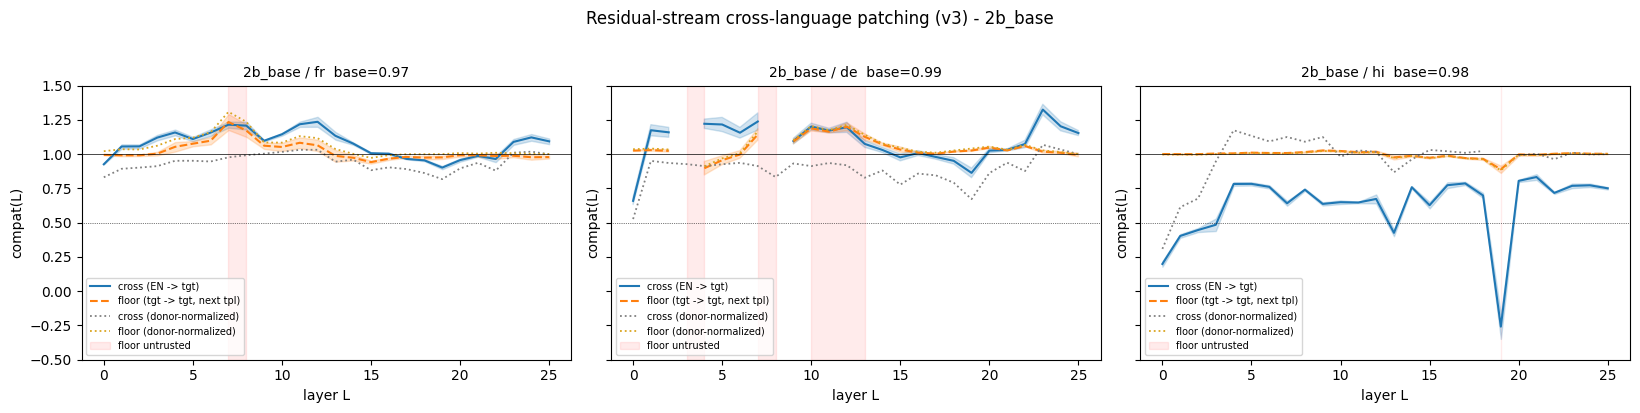

In [14]:
# RUN 1: run the PREFLIGHT cell above first.
MODEL_KEY = "2b_base"
model, tok = load_model(MODEL_KEY)
_ = load_exp14_cache(MODEL_KEY)

ok, _c = self_test(model, tok)
assert ok, "SELF-TEST FAILED: hook is broken. STOP before running the sweep."

for lang in TARGET_LANGS:
    for seed in SEEDS:
        try:
            run_one(model, tok, MODEL_KEY, lang, seed)
        except LangUnavailable as e:
            print(f"[SKIP] {lang}: {e}")
            break

print()
print("=========== 2B SUMMARY ===========")
print_summary_table(model_keys=[MODEL_KEY])
print_compact_table(model_keys=[MODEL_KEY])
print_template_breakdown(MODEL_KEY)
plot_model(MODEL_KEY)
free_model(model)

In [16]:
import json, numpy as np
for lg in ["fr", "de", "hi"]:
    rs = [json.load(open(f"exp16_v3_results/2b_base_{lg}_s{s}.json")) for s in (0, 7, 13)]
    den = np.mean([r["clean_mean"] for r in rs]) - np.mean([r["ablated_mean"] for r in rs], axis=0)
    print(lg, "clean-ablated per L:", " ".join(f"{x:+.1f}" for x in den))

fr clean-ablated per L: +3.1 +1.9 +2.1 +1.6 +1.6 +2.1 +1.6 +1.5 +1.6 +3.8 +2.8 +2.0 +1.8 +1.8 +2.9 +2.5 +3.2 +4.3 +3.3 +3.5 +5.3 +6.9 +3.7 +4.7 +3.5 +3.8
de clean-ablated per L: +2.2 +2.4 +2.3 +1.0 +1.6 +1.8 +2.4 +1.6 +0.8 +3.2 +1.8 +2.2 +1.9 +1.9 +3.3 +2.2 +3.2 +3.5 +2.8 +1.9 +3.0 +5.6 +2.5 +2.3 +3.5 +3.6
hi clean-ablated per L: +3.9 +4.1 +4.1 +2.9 +4.2 +4.5 +4.6 +3.2 +4.4 +3.2 +4.1 +3.8 +4.1 +2.7 +6.6 +3.6 +5.8 +6.3 +4.4 +1.3 +7.5 +8.3 +5.5 +5.8 +6.2 +5.6


## RUN 2: 9B base, 9B-it, 27B-it (only after inspecting RUN 1)

[load] 9b_base  <-  /home/models/gemma-2-9b


Loading weights: 100%|██████████| 464/464 [00:01<00:00, 367.11it/s]


[load] ready in 2.5s  n_layers=42  d_model=3584
[exp14 cache] exp14_results/9b_base.json not found (fine: prompts are built fresh)
[self-test] 6 EN prompts, mean clean logit-diff = +4.7708
  L=  0  patched=+4.7708  ablated=+2.6042  compat=+1.0000  ok=True
  L= 21  patched=+4.7708  ablated=+0.9583  compat=+1.0000  ok=True
  L= 41  patched=+4.7708  ablated=+0.0000  compat=+1.0000  ok=True
[self-test] all_ok = True
[run_one] cache hit 9b_base_fr_s0.json
[baseline] 9b_base fr s7: acc=1.000  (IO listed first 1.000 | second 1.000)  gate 0.75
[9b_base fr s7] 20/120  0.40 prompts/s  eta=250s
[9b_base fr s7] 40/120  0.40 prompts/s  eta=200s
[9b_base fr s7] 60/120  0.40 prompts/s  eta=150s
[9b_base fr s7] 80/120  0.40 prompts/s  eta=100s
[9b_base fr s7] 100/120  0.40 prompts/s  eta=50s
[9b_base fr s7] 120/120  0.40 prompts/s  eta=0s
[diag] clean logit-diff by template (target): +5.64  +5.76  +5.22  +3.95  +3.92  +6.12
[run_one] wrote 9b_base_fr_s7.json + 9b_base_fr_s7.npz
[baseline] 9b_base fr s

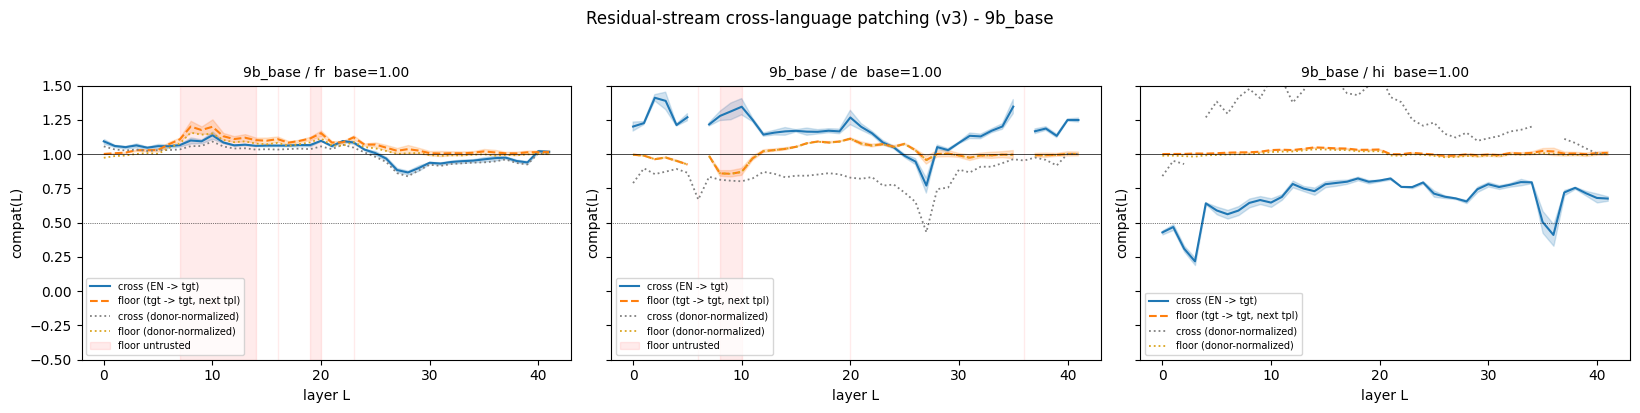

[load] 9b_it  <-  /home/models/gemma-2-9b-it


Loading weights: 100%|██████████| 464/464 [00:12<00:00, 35.82it/s]


[load] ready in 13.9s  n_layers=42  d_model=3584
[exp14 cache] exp14_results/9b_it.json not found (fine: prompts are built fresh)
[self-test] 6 EN prompts, mean clean logit-diff = +6.6562
  L=  0  patched=+6.6562  ablated=+3.2083  compat=+1.0000  ok=True
  L= 21  patched=+6.6562  ablated=+1.8125  compat=+1.0000  ok=True
  L= 41  patched=+6.6562  ablated=+0.0000  compat=+1.0000  ok=True
[self-test] all_ok = True
[baseline] 9b_it fr s0: acc=0.992  (IO listed first 1.000 | second 0.985)  gate 0.75
[9b_it fr s0] 20/120  0.40 prompts/s  eta=250s
[9b_it fr s0] 40/120  0.40 prompts/s  eta=200s
[9b_it fr s0] 60/120  0.40 prompts/s  eta=150s
[9b_it fr s0] 80/120  0.40 prompts/s  eta=100s
[9b_it fr s0] 100/120  0.40 prompts/s  eta=50s
[9b_it fr s0] 120/120  0.40 prompts/s  eta=0s
[diag] clean logit-diff by template (target): +7.32  +8.88  +8.11  +6.34  +5.92  +8.71
[run_one] wrote 9b_it_fr_s0.json + 9b_it_fr_s0.npz
[baseline] 9b_it fr s7: acc=1.000  (IO listed first 1.000 | second 1.000)  gate 0

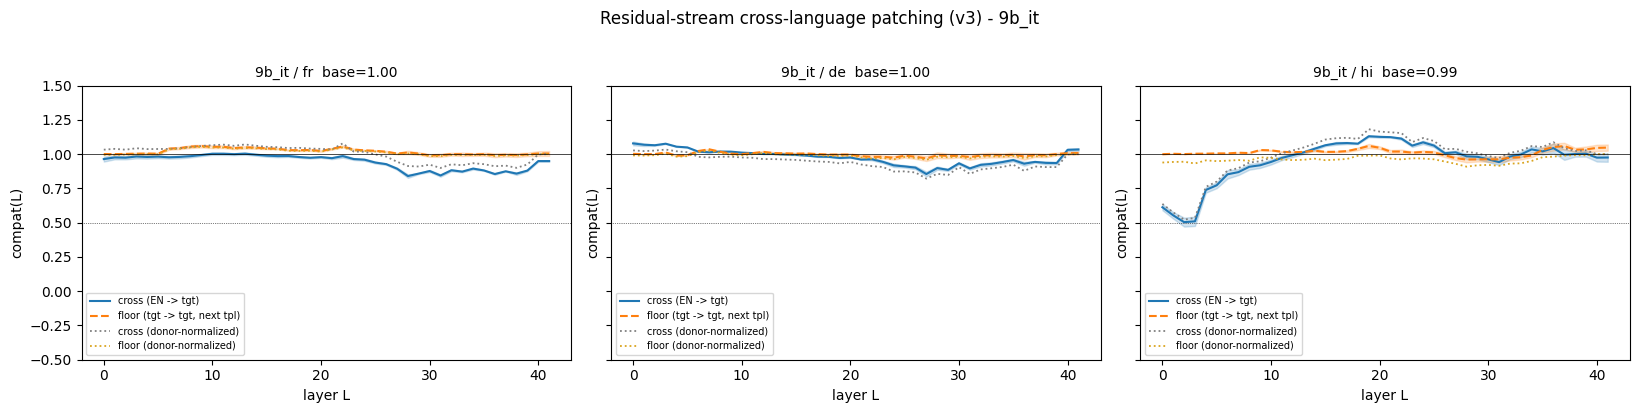


=========== FULL CROSS-SCALE SUMMARY ===========

model    lang   nL  base floor-ok L  split  verdict
2b_base  fr     26  0.97    24/26        -  PARTIAL (24/26 layers floor-ok)
2b_base  de     26  0.99    18/26        -  PARTIAL (18/26 layers floor-ok)
2b_base  hi     26  0.98    25/26        0  PARTIAL (25/26 layers floor-ok)
9b_base  fr     42  1.00    30/42        -  PARTIAL (30/42 layers floor-ok)
9b_base  de     42  1.00    36/42        -  PARTIAL (36/42 layers floor-ok)
9b_base  hi     42  1.00    42/42        0  TRUSTED
9b_it    fr     42  1.00    42/42        -  TRUSTED
9b_it    de     42  1.00    42/42        -  TRUSTED
9b_it    hi     42  0.99    42/42        -  TRUSTED


In [17]:
# RUN 2: only after RUN 1 looks sane. Per-(model, lang, seed) caching makes interruption / restart safe.
for MODEL_KEY in ["9b_base", "9b_it"]:
    model, tok = load_model(MODEL_KEY)
    _ = load_exp14_cache(MODEL_KEY)

    ok, _c = self_test(model, tok)
    if not ok:
        print(f"[WARNING] self-test failed on {MODEL_KEY}: skipping its sweep")
        free_model(model)
        continue

    for lang in TARGET_LANGS:
        for seed in SEEDS:
            try:
                run_one(model, tok, MODEL_KEY, lang, seed)
            except LangUnavailable as e:
                print(f"[SKIP] {lang}: {e}")
                break

    print()
    print(f"=========== {MODEL_KEY} SUMMARY ===========")
    print_summary_table(model_keys=[MODEL_KEY])
    print_template_breakdown(MODEL_KEY)
    plot_model(MODEL_KEY)
    free_model(model)

print()
print("=========== FULL CROSS-SCALE SUMMARY ===========")
print_compact_table()